# 17 — Referencias: peldaños 1 y 2 de la escalera

Primer circuito completo del modelado: dos modelos simples se entrenan, predicen sobre validación y se evalúan con `src/evaluacion.py` (notebook 16). Son los dos primeros peldaños de la escalera de complejidad, en la que cada modelo agrega una sola cosa al anterior:

| Peldaño | Modelo | Qué agrega | Pregunta |
|-|-|-|-|
| 1 | Umbral sobre el p10 de C13 | Una sola variable física | ¿Cuánto se logra solo con "hay nubes frías cerca"? |
| 2 | Regresión logística sobre estadísticas de parche, L = 2, 3, 4 | Las cinco bandas y su evolución, sin estructura espacial | ¿Aportan las demás bandas y la historia? |
| 3 | CNN plana (`18-cnn_plana`) | Estructura espacial | ¿Importa dónde está cada cosa en el parche? |
| 4 | ResNet (`19-resnet`) | Profundidad y conexiones residuales | ¿Una red más profunda aprende algo que la plana no? |

Todo lo de esta notebook se evalúa en **validación**. Prueba sigue cerrada hasta S11; los valores de validación sirven para elegir la regularización y el umbral de decisión, no son resultados finales.

## Decisiones

| # | Decisión | Motivo |
|-|-|-|
| 1 | **Datos de entrenamiento**: todos los pares de train, ponderados para que positivos, difíciles y aleatorios pesen 1 : 2 : 2 | Es la proporción con que se muestrean las épocas de las redes; ponderar todos los pares equivale a muestrear infinitas épocas. Así los cuatro peldaños ven los mismos datos (cada peldaño cambia una sola cosa) y sus probabilidades quedan en la misma escala, la que supone la grilla del umbral de decisión (0.01–0.99). Entrenar con la proporción real (0.34 %) daría probabilidades casi todas bajo 0.01 y el modelo nunca alertaría con esa grilla |
| 2 | **Sin hora** en la escalera; variante "logística + hora" aparte, como diagnóstico | La CNN y la ResNet no reciben la hora. Si los peldaños 1 y 2 la tuvieran, la comparación logística → CNN mezclaría la estructura espacial con la pérdida de la hora. La variante mide cuánto aporta la hora por sí sola. El AUC de 0.756 del EDA (`12-dataset_eda`) se calculó controlando la hora (aleatorios de la misma hora), no usándola como variable |
| 3 | **Variables de la logística**: por banda e instante, p10, p50, p90 y desvío estándar de la temperatura de brillo en el parche 32 × 32 | Incluye el p10 de C13, de modo que el peldaño 2 contiene al 1: si la logística perdiera contra el umbral, no sería por faltarle su variable. Sin estructura espacial por construcción. Fan et al. (2024) usan una logística como línea base pero sobre los píxeles aplanados; aquí no se hace así porque serían hasta 20,480 variables por par y, al ver la posición de cada píxel, el modelo mezclaría los peldaños 2 y 3 |
| 4 | **Peldaño 1** = logística con una sola variable (p10 de C13), sin regularización | Convierte el p10 en una probabilidad en la misma escala que el resto, sin elegir rangos. Como la relación es monótona (más frío, más probable), la forma exacta de la curva no cambia qué pares alertan; solo importa dónde se corta |
| 5 | **Regularización** de la logística (L2): C en {10⁻⁴, …, 10²}, elegido por el **PR-AUC** máximo en validación; a igual PR-AUC, el C más chico. El umbral de decisión se sigue eligiendo por CSI con el modelo ya elegido. El mismo criterio elige la mejor logística entre L = 2, 3, 4 para los diagnósticos (Secciones 4.1, 7–9) | Criterio de selección común a toda la escalera (cambio del 14-oct-2026; antes CSI): en validación el CSI es muy ruidoso (IC desde ~0, umbral óptimo inestable), y elegir el máximo entre muchas configuraciones —o entre épocas en las redes— premia la suerte con pocos episodios. El PR-AUC usa todos los positivos, no depende del umbral y se arma con los mismos ingredientes que el CSI (precisión = 1 − FAR, exhaustividad = POD): es el área bajo la curva del diagrama de desempeño (Roebber, 2009). A igual desempeño se prefiere el modelo más regularizado. El CSI de validación sale algo optimista y no se reporta como resultado |
| 6 | **Train por L**: el peldaño 1 usa los pares con L_max ≥ 2 (solo mira t); cada logística, los pares con L_max ≥ L | Igual que las redes (`15-cargador`). Validación es el conjunto común L_max = 4 para todos |

## 0. Configuración

Requiere scikit-learn y, para el registro de experimentos, MLflow (`pip install scikit-learn==1.7.2 mlflow`). Si MLflow no está instalado, la notebook corre igual y solo omite el registro. Las corridas se guardan en `mlruns/mlflow.db` (SQLite; las versiones recientes de MLflow ya no aceptan el registro en carpetas) y los archivos adjuntos en `mlruns/artefactos/`, en la raíz del repositorio y fuera de git. Para verlas: `mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db` desde la raíz.

In [1]:
import sys, pathlib
_raiz = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / ".gitignore").exists())
sys.path.insert(0, str(_raiz))
import entorno

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ       = _raiz
RUTA_DS    = RAIZ / "datasets"
RUTA_CACHE = RAIZ / "data" / "cache"
RUTA_EST   = RUTA_CACHE / "estadisticas_parche"
RUTA_SAL   = RAIZ / "modelo" / "salidas_17"
RUTA_SAL.mkdir(exist_ok=True)

sys.path.insert(0, str(RAIZ / "src"))
from cache_imagenes import Cache
from cargador import NG, L_COMUN, preparar_pares, cod10
import referencias as rf
import evaluacion as ev
from paleta import ROL, PALETA, aplicar_estilo
aplicar_estilo()

B = ev.B_DEFECTO          # 10,000 réplicas (decisión 1 de S4a)
SEMILLA = 42

try:
    import mlflow
    (RAIZ / "mlruns").mkdir(exist_ok=True)
    mlflow.set_tracking_uri(f"sqlite:///{(RAIZ / 'mlruns' / 'mlflow.db').as_posix()}")
    NOMBRE_EXP = "s5-referencias-validacion"
    if mlflow.get_experiment_by_name(NOMBRE_EXP) is None:
        mlflow.create_experiment(NOMBRE_EXP, artifact_location=(RAIZ / "mlruns" / "artefactos").as_uri())
    mlflow.set_experiment(NOMBRE_EXP)
    MLFLOW = True
except ImportError:
    MLFLOW = False
print("MLflow:", MLFLOW)

zs        = pd.read_csv(RAIZ / "data_ingestion" / "satellite" / "normalizacion_zscore.csv")
cache     = Cache(RUTA_CACHE, zs, en_memoria=False)
indice    = pd.read_parquet(RUTA_DS / "indice_completo.parquet")
atributos = pd.read_parquet(RUTA_DS / "negativos_atributos.parquet")
print(f"Caché {cache.img.shape}; índice {len(indice):,} pares; atributos {len(atributos):,}")

MLflow: True
Caché (104745, 5, 60, 50); índice 4,029,925 pares; atributos 3,973,266


## 1. Estadísticas de parche

Las estadísticas dependen solo de la imagen y de la estación, no del par, así que se calculan una sola vez para todo el caché (104,745 imágenes × estaciones × 5 bandas × 4 estadísticas) y se guardan en `data/cache/estadisticas_parche.npy`. Cada par las toma de las filas de su historia.

**Control**: el p10 de C13 en t de cada par debe coincidir con la columna `p10_c13` de `negativos_atributos.parquet`, calculada en `14-negativos_dificiles` con `percentil_banda`. Si coinciden, la variable del peldaño 1 es exactamente la del criterio `nube_fria` y la del EDA.

In [3]:
if not RUTA_EST.with_suffix(".npy").exists():
    try:
        from tqdm.auto import tqdm
    except ImportError:
        tqdm = None
    t0 = time.time()
    est, codigos = rf.calcular_estadisticas(cache, lote=100, progreso=tqdm)
    rf.guardar_estadisticas(RUTA_EST, est, codigos, cache.bandas)
    print(f"Calculadas en {(time.time() - t0) / 60:.1f} min")
est, meta_est = rf.leer_estadisticas(RUTA_EST)
codigos, bandas = meta_est["estaciones"], meta_est["bandas"]
print(est.shape, f"{est.nbytes / 1e9:.2f} GB", bandas)

(104745, 63, 5, 4) 0.53 GB ['CMI_C08', 'CMI_C09', 'CMI_C10', 'CMI_C13', 'CMI_C14']


## 2. Conjuntos

Train con L = 2, 3 y 4 (cada uno con los pares que tienen su historia) y validación con el conjunto común L_max = 4. Se cuentan también las estaciones por período en el índice, sin Nueva Generación, para identificar la estación que aparece en las etiquetas (62) y no en el entrenamiento (61).

In [4]:
conj = {("train", L): preparar_pares(indice, atributos, cache, "train", L) for L in (2, 3, 4)}
conj[("val", 4)] = preparar_pares(indice, atributos, cache, "val", L_COMUN)
val = conj[("val", 4)]
for k, d in conj.items():
    print(f"{k[0]:5s} L={k[1]}: {len(d):>9,} pares, {int(d.etiqueta.sum()):>5,} positivos, "
          f"{d.codigoestacion.nunique()} estaciones; bolsas {d.bolsa.value_counts().to_dict()}")

ix = indice.assign(codigoestacion=cod10(indice.codigoestacion))
ix = ix[ix.codigoestacion != NG]
por_periodo = ix.groupby("periodo").codigoestacion.agg(set)
todas = set().union(*por_periodo)
for p, s in por_periodo.items():
    print(f"{p}: {len(s)} estaciones; faltan {sorted(todas - s)}")

train L=2: 1,244,157 pares, 4,249 positivos, 61 estaciones; bolsas {'aleatorio': 1143575, 'dificil': 96333, 'positivo': 4249}
train L=3: 1,241,422 pares, 4,202 positivos, 61 estaciones; bolsas {'aleatorio': 1141511, 'dificil': 95709, 'positivo': 4202}
train L=4: 1,238,827 pares, 4,155 positivos, 61 estaciones; bolsas {'aleatorio': 1139430, 'dificil': 95242, 'positivo': 4155}
val   L=4:   325,425 pares, 1,487 positivos, 62 estaciones; bolsas {'aleatorio': 273345, 'dificil': 50593, 'positivo': 1487}
test: 62 estaciones; faltan []
train: 61 estaciones; faltan ['2120000136']
val: 62 estaciones; faltan []


In [5]:
p10_t = rf.p10_c13(conj[("train", 2)], est, codigos, bandas, 2)
dif = np.abs(p10_t - conj[("train", 2)]["p10_c13"].to_numpy())
print(f"máxima diferencia con p10_c13 de 14-negativos_dificiles: {dif.max():.2e} K")
assert dif.max() < 1e-3, "El p10 de C13 no coincide con el de 14"

máxima diferencia con p10_c13 de 14-negativos_dificiles: 1.53e-05 K


## 3. Peldaño 1: umbral sobre el p10 de C13

Logística con una sola variable sobre train (L_max ≥ 2), ponderada 1 : 2 : 2. La probabilidad que devuelve es una función monótona del p10: el umbral de decisión sobre la probabilidad equivale a un umbral en kelvin, que se informa para leerlo físicamente.

In [6]:
def evaluar_val(nombre, p, extra=None):
    "Umbral de decisión en validación + evaluación por pares con bootstrap de días pluviométricos."
    y = val.etiqueta.to_numpy()
    sel = ev.elegir_umbral(y, p)
    planas, art = ev.evaluar(val.timestamp, y, p, sel["umbral"], conjunto="val", B=B, semilla=SEMILLA)
    planas["val_csi_meseta_desde"], planas["val_csi_meseta_hasta"] = sel["meseta_desde"], sel["meseta_hasta"]
    sel["curva"].to_csv(RUTA_SAL / f"curva_{nombre}.csv", index=False)
    pd.DataFrame({"codigoestacion": val.codigoestacion, "timestamp": val.timestamp,
                  "etiqueta": y, "p": p}).to_parquet(RUTA_SAL / f"pred_val_{nombre}.parquet")
    if MLFLOW:
        with mlflow.start_run(run_name=nombre):
            mlflow.log_params({"modelo": nombre, "ponderacion": "1:2:2", **(extra or {})})
            mlflow.log_metrics({k: float(v) for k, v in planas.items() if np.isfinite(v)})
            mlflow.log_artifact(str(RUTA_SAL / f"curva_{nombre}.csv"))
            mlflow.log_artifact(str(RUTA_SAL / f"pred_val_{nombre}.parquet"))
    return sel, planas, art

def resumen(planas):
    k = ["umbral", "csi", "pod", "far", "ets", "auc", "pr_auc"]
    out = {m: planas[f"val_{m}"] for m in k}
    for m in k[1:]:
        out[f"{m}_ic"] = f"[{planas[f'val_{m}_ic_inf']:.3f}, {planas[f'val_{m}_ic_sup']:.3f}]"
    out["n_alertas"] = planas["val_n_alertas"]
    return out

resultados = {}

In [7]:
tr = conj[("train", 2)]
w2 = rf.pesos_muestreo(tr.bolsa)
x1_tr = rf.p10_c13(tr, est, codigos, bandas, 2)
t0 = time.time()
m1 = rf.ajustar(x1_tr, tr.etiqueta.to_numpy(), w2, C=None)
x1_val = rf.p10_c13(val, est, codigos, bandas, 4)
p1 = rf.predecir(m1, x1_val)
sel1, planas1, art1 = evaluar_val("peldano1_umbral_c13", p1, {"L": 0, "variables": "p10_C13"})
resultados["1 · umbral C13"] = resumen(planas1)

# umbral equivalente en kelvin: el p10 más cálido que todavía alerta
k_equiv = x1_val[p1 >= sel1["umbral"]].max()
print(f"{time.time() - t0:.0f} s | umbral de decisión {sel1['umbral']:.2f} ≡ p10 de C13 ≤ {k_equiv:.1f} K "
      f"(meseta {sel1['meseta_desde']:.2f}–{sel1['meseta_hasta']:.2f})")
pd.Series(resultados["1 · umbral C13"])

100 s | umbral de decisión 0.36 ≡ p10 de C13 ≤ 208.3 K (meseta 0.36–0.36)


umbral                  0.36
csi                  0.02433
pod                 0.032952
far                 0.914931
ets                 0.023053
auc                 0.776079
pr_auc              0.019249
csi_ic        [0.000, 0.042]
pod_ic        [0.000, 0.072]
far_ic        [0.864, 1.000]
ets_ic       [-0.000, 0.040]
auc_ic        [0.689, 0.838]
pr_auc_ic     [0.005, 0.032]
n_alertas                576
dtype: object

## 4. Peldaño 2: regresión logística sobre estadísticas de parche

Para cada L se ajusta la logística con los siete valores de C y se elige el de mayor **PR-AUC** en validación (decisión 5); a igual PR-AUC, el C más chico. Luego, con el C elegido, se elige el umbral de decisión por CSI. La tabla muestra el PR-AUC y, como referencia, el CSI máximo por C: si el mejor C cae en un extremo de la grilla, la grilla se queda corta y conviene ampliarla.


In [8]:
busqueda, modelos2, x_val = [], {}, {}
for L in (2, 3, 4):
    tr = conj[("train", L)]
    x_tr = rf.variables_pares(tr, est, codigos, L)
    y_tr, w = tr.etiqueta.to_numpy(), rf.pesos_muestreo(tr.bolsa)
    x_val[L] = rf.variables_pares(val, est, codigos, L_COMUN)[:, -L * len(bandas) * 4:]   # últimos L instantes
    for Cr in rf.GRILLA_C:
        t0 = time.time()
        m = rf.ajustar(x_tr, y_tr, w, Cr)
        p = rf.predecir(m, x_val[L])
        s = ev.elegir_umbral(val.etiqueta.to_numpy(), p)
        _, ap = ev.auc_pr(val.etiqueta.to_numpy(), p)
        busqueda.append({"L": L, "C": Cr, "pr_auc_val": ap, "csi_val": s["csi_max"], "umbral": s["umbral"], "seg": time.time() - t0})
        modelos2[(L, Cr)] = m
    print(f"L = {L}: {x_tr.shape[1]} variables, {len(tr):,} pares de train")
busqueda = pd.DataFrame(busqueda)
busqueda.to_csv(RUTA_SAL / "busqueda_C.csv", index=False)
busqueda.pivot(index="C", columns="L", values=["pr_auc_val", "csi_val"]).round(4)

L = 2: 40 variables, 1,244,157 pares de train
L = 3: 60 variables, 1,241,422 pares de train
L = 4: 80 variables, 1,238,827 pares de train


pr_auc_val                 csi_val                
L                 2       3       4       2       3       4
C                                                          
0.0001       0.0148  0.0149  0.0151  0.0195  0.0195  0.0195
0.0010       0.0155  0.0162  0.0167  0.0191  0.0199  0.0191
0.0100       0.0178  0.0183  0.0188  0.0207  0.0203  0.0209
0.1000       0.0190  0.0199  0.0209  0.0214  0.0274  0.0297
1.0000       0.0204  0.0219  0.0233  0.0262  0.0290  0.0306
10.0000      0.0209  0.0225  0.0242  0.0260  0.0261  0.0284
100.0000     0.0206  0.0224  0.0242  0.0257  0.0264  0.0279

In [9]:
# decisión 5: PR-AUC máximo; a igual PR-AUC (4 decimales), el C más chico
mejor_C = (busqueda.assign(pr=busqueda.pr_auc_val.round(4))
           .sort_values(["L", "pr", "C"], ascending=[True, False, True])
           .groupby("L").head(1).set_index("L")["C"])
for L in (2, 3, 4):
    if mejor_C[L] in (min(rf.GRILLA_C), max(rf.GRILLA_C)):
        print(f"Aviso: L = {L} elige C = {mejor_C[L]}, en el borde de la grilla")
print("C elegido por L:", mejor_C.to_dict())
p2 = {}
for L in (2, 3, 4):
    p2[L] = rf.predecir(modelos2[(L, mejor_C[L])], x_val[L])
    _, planas, _ = evaluar_val(f"peldano2_logistica_L{L}", p2[L], {"L": L, "C": mejor_C[L], "variables": "p10,p50,p90,desvio"})
    resultados[f"2 · logística L={L}"] = resumen(planas)
pd.DataFrame(resultados).T

C elegido por L: {2: 10.0, 3: 10.0, 4: 10.0}


,umbral,csi,pod,far,ets,auc,pr_auc,csi_ic,pod_ic,far_ic,ets_ic,auc_ic,pr_auc_ic,n_alertas
1 · umbral C13,0.36,0.02433,0.032952,0.914931,0.023053,0.776079,0.019249,"[0.000, 0.042]","[0.000, 0.072]","[0.864, 1.000]","[-0.000, 0.040]","[0.689, 0.838]","[0.005, 0.032]",576
2 · logística L=2,0.41,0.025992,0.073974,0.961471,0.022981,0.823379,0.02088,"[0.004, 0.047]","[0.013, 0.119]","[0.924, 0.995]","[0.002, 0.043]","[0.766, 0.859]","[0.007, 0.040]",2855
2 · logística L=3,0.46,0.026129,0.047075,0.944532,0.024028,0.820126,0.022466,"[0.001, 0.048]","[0.003, 0.084]","[0.892, 0.997]","[-0.000, 0.046]","[0.763, 0.856]","[0.007, 0.045]",1262
2 · logística L=4,0.48,0.028421,0.047075,0.933078,0.026532,0.815801,0.024185,"[0.001, 0.051]","[0.002, 0.084]","[0.875, 0.997]","[0.000, 0.049]","[0.760, 0.851]","[0.007, 0.051]",1046


### 4.1 Variante de diagnóstico: logística + hora

Fuera de la escalera. Se agrega el seno y el coseno de la hora local de t a la logística con el L y el C elegidos por PR-AUC (decisión 5). La diferencia con la logística sin hora estima cuánto aporta la hora por sí sola.

In [10]:
L_h = int(pd.DataFrame(resultados).T.filter(like="logística", axis=0)["pr_auc"].astype(float).idxmax().split("=")[1])   # decisión 5
tr = conj[("train", L_h)]
x_tr_h = np.hstack([rf.variables_pares(tr, est, codigos, L_h), rf.variables_hora(tr.timestamp)])
m_h = rf.ajustar(x_tr_h, tr.etiqueta.to_numpy(), rf.pesos_muestreo(tr.bolsa), mejor_C[L_h])
p_h = rf.predecir(m_h, np.hstack([x_val[L_h], rf.variables_hora(val.timestamp)]))
_, planas_h, _ = evaluar_val(f"diagnostico_logistica_L{L_h}_hora", p_h, {"L": L_h, "C": mejor_C[L_h], "variables": "p10,p50,p90,desvio+hora"})
resultados[f"diag · logística L={L_h} + hora"] = resumen(planas_h)
tabla = pd.DataFrame(resultados).T
tabla

,umbral,csi,pod,far,ets,auc,pr_auc,csi_ic,pod_ic,far_ic,ets_ic,auc_ic,pr_auc_ic,n_alertas
1 · umbral C13,0.36,0.02433,0.032952,0.914931,0.023053,0.776079,0.019249,"[0.000, 0.042]","[0.000, 0.072]","[0.864, 1.000]","[-0.000, 0.040]","[0.689, 0.838]","[0.005, 0.032]",576
2 · logística L=2,0.41,0.025992,0.073974,0.961471,0.022981,0.823379,0.02088,"[0.004, 0.047]","[0.013, 0.119]","[0.924, 0.995]","[0.002, 0.043]","[0.766, 0.859]","[0.007, 0.040]",2855
2 · logística L=3,0.46,0.026129,0.047075,0.944532,0.024028,0.820126,0.022466,"[0.001, 0.048]","[0.003, 0.084]","[0.892, 0.997]","[-0.000, 0.046]","[0.763, 0.856]","[0.007, 0.045]",1262
2 · logística L=4,0.48,0.028421,0.047075,0.933078,0.026532,0.815801,0.024185,"[0.001, 0.051]","[0.002, 0.084]","[0.875, 0.997]","[0.000, 0.049]","[0.760, 0.851]","[0.007, 0.051]",1046
diag · logística L=4 + hora,0.31,0.021851,0.214526,0.976249,0.017721,0.799983,0.016925,"[0.008, 0.038]","[0.106, 0.289]","[0.958, 0.992]","[0.005, 0.032]","[0.752, 0.834]","[0.007, 0.030]",13431


## 5. Comparaciones pareadas en validación

Las comparaciones fijadas para prueba (decisión 3 de S4a) se calculan aquí sobre validación, solo como orientación: logística frente a umbral y L = 3 y L = 4 frente a L = 2. Los mismos días pluviométricos se sortean para los dos modelos de cada par.

In [11]:
y_val = val.etiqueta.to_numpy()
def tablas(p, nombre):
    u = ev.elegir_umbral(y_val, p)["umbral"]
    return ev.tablas_por_bloque(val.timestamp, y_val, p, u)
bl, t1 = tablas(p1, "1")
pesos = ev.pesos_bootstrap(len(bl), B=B, semilla=SEMILLA)
t2 = {L: ev.tablas_por_bloque(val.timestamp, y_val, p2[L], ev.elegir_umbral(y_val, p2[L])["umbral"], bloques=bl)[1] for L in (2, 3, 4)}
filas = []
for nombre, A, Bt in [(f"logística L={L} − umbral", t2[L], t1) for L in (2, 3, 4)] + \
                     [("logística L=3 − L=2", t2[3], t2[2]), ("logística L=4 − L=2", t2[4], t2[2])]:
    c = ev.comparar_pareado(A, Bt, pesos)
    filas.append({"comparación": nombre, "ΔCSI": round(c["delta"], 4),
                  "IC 95 %": f"[{c['ic_inf']:.4f}, {c['ic_sup']:.4f}]", "gana el primero": f"{c['frac_gana_A']:.1%}"})
pd.DataFrame(filas)

,comparación,ΔCSI,IC 95 %,gana el primero
0,logística L=2 − umbral,0.0017,"[-0.0098, 0.0245]",70.2%
1,logística L=3 − umbral,0.0018,"[-0.0064, 0.0188]",73.8%
2,logística L=4 − umbral,0.0041,"[-0.0048, 0.0205]",82.9%
3,logística L=3 − L=2,0.0001,"[-0.0075, 0.0062]",40.5%
4,logística L=4 − L=2,0.0024,"[-0.0066, 0.0094]",57.5%


## 6. Curvas de CSI según el umbral de decisión

Para cada modelo, el CSI en validación a lo largo de la grilla. La meseta marca el rango de umbrales con el CSI máximo; el umbral elegido es su punto medio. Una curva con un pico agudo indica un umbral sensible a pequeños cambios.

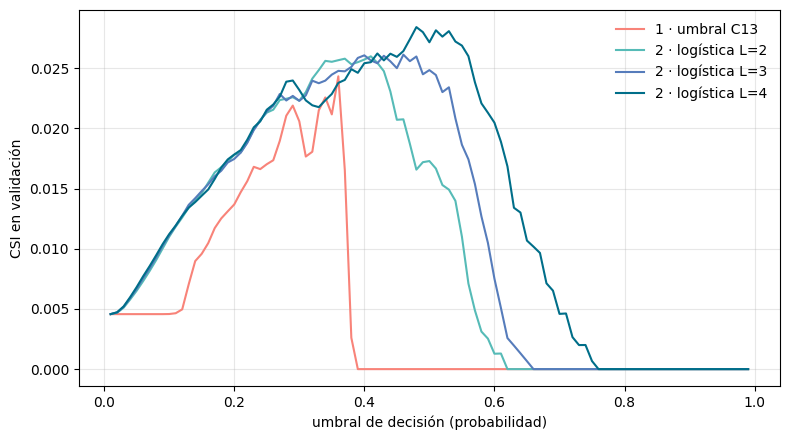

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colores = {"peldano1_umbral_c13": ROL["umbral"], "peldano2_logistica_L2": PALETA["wi-iceblue"],
           "peldano2_logistica_L3": PALETA["wi-darkblue"], "peldano2_logistica_L4": PALETA["wwu-blue"]}
etiquetas = {"peldano1_umbral_c13": "1 · umbral C13", "peldano2_logistica_L2": "2 · logística L=2",
             "peldano2_logistica_L3": "2 · logística L=3", "peldano2_logistica_L4": "2 · logística L=4"}
for nombre, color in colores.items():
    cur = pd.read_csv(RUTA_SAL / f"curva_{nombre}.csv")
    ax.plot(cur.umbral, cur.csi, color=color, label=etiquetas[nombre])
ax.set_xlabel("umbral de decisión (probabilidad)"); ax.set_ylabel("CSI en validación")
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(RUTA_SAL / "img-curvas_csi_umbral.png", dpi=150)

## 7. Métricas por evento y estratos

Episodios de validación construidos con la intensidad de las etiquetas y los umbrales operativos (como en `16-evaluacion`, Sección 8), para el peldaño 1 y la mejor logística. Estratos: noche (19:00–06:59 local), terciles de umbral, temporada y nube fría (p10 de C13 ≤ 228.2 K; episodios por su primer par positivo, avisos por su primera alerta).

In [13]:
etiquetas_gt = pd.read_parquet(RAIZ / "data_ingestion" / "ground_truth" / "etiquetas_ground_truth.parquet")
lab = etiquetas_gt.assign(codigoestacion=etiquetas_gt.codigoestacion.astype(str))
lab = lab[lab.codigoestacion != NG]
umb = pd.read_csv(RAIZ / "data_ingestion" / "ground_truth" / "umbral_operativo_por_estacion.csv",
                  dtype={"codigoestacion": str}).set_index("codigoestacion")["umbral_mm_h"]
umb = umb[umb.index.isin(lab.codigoestacion.unique())]
episodios, fuertes = ev.episodios_lluvia(lab, umb)
val["id_episodio"], _ = ev.asignar_episodio(val, fuertes)
assert ((val.id_episodio >= 0) == (val.etiqueta == 1)).all(), "Asignación de episodios inconsistente con las etiquetas"
grupo_umbral, cortes = ev.terciles_umbral(umb)
p10_par = val.set_index(["codigoestacion", "timestamp"])["p10_c13"]
print(f"{(val.etiqueta == 1).sum():,} positivos en {val.loc[val.etiqueta == 1, 'id_episodio'].nunique()} episodios; "
      f"cortes de terciles de umbral: {np.round(cortes, 2)} mm/h")

1,487 positivos en 149 episodios; cortes de terciles de umbral: [5.4  6.85] mm/h


In [14]:
def estratos_modelo(p, nombre):
    y = val.etiqueta.to_numpy()
    u = ev.elegir_umbral(y, p)["umbral"]
    ep, av = ev.eventos(val.assign(y=y, p=p), episodios, u)
    bl, _ = ev.tablas_por_bloque(val.timestamp, y, p, u)
    pesos = ev.pesos_bootstrap(len(bl), B=B, semilla=SEMILLA)
    args = dict(pares=val.assign(y=y, p=p), ep=ep, avisos=av, umbral=u, pesos=pesos, bloques=bl)
    clave = lambda est_, t: pd.MultiIndex.from_arrays([est_, t])
    particiones = {
        "total":     (np.full(len(val), "total"), np.full(len(ep), "total"), np.full(len(av), "total")),
        "noche":     (ev.es_noche(val.timestamp), ev.es_noche(ep.inicio), ev.es_noche(av.t_primera)),
        "umbral":    (val.codigoestacion.map(grupo_umbral).to_numpy(), ep.codigoestacion.map(grupo_umbral).to_numpy(),
                      av.codigoestacion.map(grupo_umbral).to_numpy()),
        "temporada": (ev.temporada(val.timestamp), ev.temporada(ep.inicio), ev.temporada(av.t_primera)),
        "nube_fria": (ev.nube_fria(val.p10_c13), ev.nube_fria(p10_par.reindex(clave(ep.codigoestacion, ep.t_primer_par)).to_numpy()),
                      ev.nube_fria(p10_par.reindex(clave(av.codigoestacion, av.t_primera)).to_numpy())),
    }
    filas = []
    for part, (sp, se, sa) in particiones.items():
        r = ev.evaluar_por_estrato(**args, estrato_pares=sp, estrato_ep=se, estrato_avisos=sa)
        filas.append(r.assign(particion=part))
    out = pd.concat(filas, ignore_index=True)
    out.to_csv(RUTA_SAL / f"estratos_{nombre}.csv", index=False)
    return out, ev.resumen_anticipacion(ep)

L_best = int(tabla.filter(like="2 · logística", axis=0)["pr_auc"].astype(float).idxmax().split("=")[1])   # decisión 5
cols = ["particion", "estrato", "n_tormentas", "n_episodios", "csi", "pod_evento", "far_evento", "frac_anticipacion_1h"]
est1, ant1 = estratos_modelo(p1, "peldano1")
est2, ant2 = estratos_modelo(p2[L_best], f"peldano2_L{L_best}")
print("Anticipación, peldaño 1:", {k: round(v, 2) for k, v in ant1.items()})
print(f"Anticipación, logística L={L_best}:", {k: round(v, 2) for k, v in ant2.items()})
est1[cols].merge(est2[cols], on=["particion", "estrato"], suffixes=(" · umbral", " · logística")).round(3)

Anticipación, peldaño 1: {'n_avisados': 13, 'mediana_h': 1.83, 'q1_h': 1.5, 'q3_h': 2.17, 'frac_1h': 1.0}
Anticipación, logística L=4: {'n_avisados': 23, 'mediana_h': 1.67, 'q1_h': 1.5, 'q3_h': 2.25, 'frac_1h': 0.96}


,particion,estrato,n_tormentas · umbral,n_episodios · umbral,csi · umbral,pod_evento · umbral,far_evento · umbral,frac_anticipacion_1h · umbral,n_tormentas · logística,n_episodios · logística,csi · logística,pod_evento · logística,far_evento · logística,frac_anticipacion_1h · logística
0,total,total,1487,149,0.024,0.087248322147651,0.9078014184397163,1.0,1487,149,0.028,0.15436241610738255,0.9590017825311943,0.9565217391304348
1,noche,False,888,72,0.000,0.0,1.0,nan,888,72,0.013,0.1527777777777778,0.9733009708737864,0.9090909090909091
2,noche,True,599,77,0.044,0.16883116883116883,0.9051094890510949,1.0,599,77,0.055,0.15584415584415584,0.9194630872483222,1.0
3,umbral,alto,550,51,0.030,0.09803921568627451,0.8936170212765957,1.0,550,51,0.040,0.23529411764705882,0.9354838709677419,0.9166666666666666
4,umbral,bajo,423,48,0.030,0.10416666666666667,0.9180327868852459,1.0,423,48,0.029,0.125,0.9702970297029703,1.0
5,umbral,medio,514,50,0.012,0.06,0.9090909090909091,1.0,514,50,0.017,0.1,0.9710982658959537,1.0
6,temporada,DEF,383,36,0.000,0.0,1.0,nan,383,36,0.008,0.1111111111111111,0.9811320754716981,0.75
7,temporada,SON,1104,113,0.030,0.11504424778761062,0.9057971014492754,1.0,1104,113,0.037,0.168141592920354,0.9455587392550143,1.0
8,nube_fria,False,1107,117,0.000,0.0,nan,nan,1107,117,0.013,0.09401709401709402,0.9669669669669669,0.9090909090909091
9,nube_fria,True,380,32,0.054,0.40625,0.9078014184397163,1.0,380,32,0.055,0.375,0.9473684210526315,1.0


### 7.1 Verificación: avisos con anticipación menor a 1 h

La logística avisó un episodio con menos de 1 h de anticipación (`frac_1h` < 1), aunque la etiqueta mira la ventana (t+1h, t+3h]. No es necesariamente un error: el par es positivo si hay lluvia fuerte *en algún momento* de la ventana, mientras que la anticipación se mide hasta el *inicio* del episodio. Un episodio largo que empieza entre t y t+1h (sin lluvia fuerte en t, por eso el par no se excluye como `en_curso`) y continúa hasta la ventana da un par positivo con anticipación menor a 1 h. La celda lista esos avisos y comprueba que todos son de ese tipo; si alguno no lo es, hay un error en `ev.eventos`.


In [20]:
# Esperado: episodio largo que empieza en (t, t+1h) y sigue hasta la ventana (t+2h, t+3h]
for nombre, p in [("umbral C13", p1), (f"logística L={L_best}", p2[L_best])]:
    u = ev.elegir_umbral(y_val, p)["umbral"]
    ep, _ = ev.eventos(val.assign(y=y_val.astype(bool), p=p), episodios, u)
    cortos = ep[ep["avisado"] & (ep["anticipacion_h"] < 1)].copy()
    print(f"{nombre}: {len(cortos)} de {int(ep['avisado'].sum())} avisados con anticipación < 1 h")
    if len(cortos) == 0:
        continue
    t, ini, fin = cortos["t_primera_alerta"], cortos["inicio"], cortos["fin"]
    cortos["duracion_ep_h"] = (fin - ini) / pd.Timedelta(hours=1) + 1 / 6
    cortos["llega_a_ventana"] = fin > t + pd.Timedelta(hours=2)
    cortos["empieza_antes_ventana"] = (ini > t) & (ini < t + pd.Timedelta(hours=1))
    cortos["caso_esperado"] = cortos["llega_a_ventana"] & cortos["empieza_antes_ventana"]
    for c in ["t_primera_alerta", "inicio", "fin"]:
        cortos[c] = cortos[c].dt.tz_convert("America/Bogota").dt.strftime("%Y-%m-%d %H:%M")
    display(cortos[["codigoestacion", "t_primera_alerta", "inicio", "fin", "anticipacion_h",
                    "duracion_ep_h", "caso_esperado"]].round(2))
    if not cortos["caso_esperado"].all():
        print("ATENCIÓN: hay avisos < 1 h que no se explican por un episodio largo → revisar ev.eventos")

umbral C13: 0 de 13 avisados con anticipación < 1 h
logística L=4: 1 de 23 avisados con anticipación < 1 h


,codigoestacion,t_primera_alerta,inicio,fin,anticipacion_h,duracion_ep_h,caso_esperado
107,2120000139,2024-12-12 15:00,2024-12-12 15:40,2024-12-12 17:10,0.67,1.67,True


**Resultado.** Un solo caso, de la logística L = 4 (el umbral sobre C13 no tiene ninguno): estación 2120000139, alerta el 12-dic-2024 a las 15:00 local, inicio de la lluvia fuerte a las 15:40 y fin a las 17:10 (episodio de 1.67 h), anticipación 0.67 h. Es el caso esperado: el episodio empezó entre t y t + 1 h y continuó hasta la ventana, así que el par es positivo y la alerta es anterior a la lluvia. No hay error en `ev.eventos`. La fracción de avisos con anticipación de al menos 1 h no es 1 por construcción; lo informativo es la mediana (1.83 h el umbral, 1.67 h la logística L = 4).

## 8. Sensibilidad al largo del bloque (decisión 2 de S4a)

Ancho del IC 95 % del CSI con bloques de 6, 12, 24 y 48 h, para los dos peldaños. Mientras el bloque es demasiado corto, el intervalo se ensancha al alargarlo (aparece la dependencia que antes se ignoraba); cuando el bloque ya contiene la dependencia, el ancho deja de crecer. Si el ancho sigue creciendo de 24 a 48 h, se pasa a bloques de 48 h y se declara la pérdida de bloques como limitación.

In [15]:
filas = []
for nombre, p in [("umbral C13", p1), (f"logística L={L_best}", p2[L_best])]:
    u = ev.elegir_umbral(y_val, p)["umbral"]
    for h in (6, 12, 24, 48):
        pl, _ = ev.evaluar(val.timestamp, y_val, p, u, conjunto="val", B=B, semilla=SEMILLA, horas_bloque=h, con_auc=False)
        filas.append({"modelo": nombre, "horas_bloque": h, "n_bloques": pl["val_n_bloques"],
                      "ancho_ic_csi": pl["val_csi_ic_sup"] - pl["val_csi_ic_inf"]})
sens = pd.DataFrame(filas)
sens.to_csv(RUTA_SAL / "sensibilidad_bloque.csv", index=False)
sens.pivot(index="horas_bloque", columns="modelo", values="ancho_ic_csi").round(4)

modelo,logística L=4,umbral C13
horas_bloque,,
6,0.0552,0.0521
12,0.0567,0.0467
24,0.0502,0.0421
48,0.0462,0.0404


## 9. Estabilidad del umbral de decisión (diagnóstico de la decisión 4 de S4a)

El umbral se re-elige en cada una de 1,000 réplicas del bootstrap. Si salta en un rango amplio, la elección del umbral es inestable y hay que declararlo.

In [16]:
for nombre, p in [("umbral C13", p1), (f"logística L={L_best}", p2[L_best])]:
    bl_u, t_bu = ev.tablas_por_bloque_y_umbral(val.timestamp, y_val, p)
    u_rep = ev.estabilidad_umbral(t_bu, ev.pesos_bootstrap(len(bl_u), B=1000, semilla=SEMILLA))
    q = np.quantile(u_rep, [0.025, 0.5, 0.975])
    print(f"{nombre}: umbral elegido {ev.elegir_umbral(y_val, p)['umbral']:.2f}; re-elegido en 1,000 réplicas: "
          f"mediana {q[1]:.2f}, 95 % central [{q[0]:.2f}, {q[2]:.2f}]")

umbral C13: umbral elegido 0.36; re-elegido en 1,000 réplicas: mediana 0.33, 95 % central [0.23, 0.36]
logística L=4: umbral elegido 0.48; re-elegido en 1,000 réplicas: mediana 0.48, 95 % central [0.18, 0.53]


## 10. Discriminación sin umbral: AUC y PR-AUC

El CSI depende del umbral de decisión y, con pocos aciertos, varía de forma irregular entre umbrales vecinos (Sección 6). Dos métricas que no dependen del umbral separan dos preguntas distintas. El **AUC** (área bajo la curva ROC) mide si el modelo ordena bien los pares: es la probabilidad de que un positivo tomado al azar reciba más probabilidad que un negativo tomado al azar (0.5 = azar, 1 = perfecto). El **PR-AUC** (precisión promedio) mide la calidad de la parte alta del ordenamiento, donde se emiten las alertas, y se lee frente a la prevalencia, que es el valor de un modelo al azar. El CSI sigue siendo la métrica principal de los resultados. El PR-AUC es además el criterio de selección de modelos en validación (decisión 5); el AUC se reporta solo como complementario, porque con tantos negativos fáciles sale alto aunque las alertas sean malas (ver la variante con hora). Ambos van con IC del mismo bootstrap por días pluviométricos (`ev.auc_pr`, `ev.bootstrap_auc_pr`, verificadas contra scikit-learn en `16-evaluacion`).

Resultados en validación (prevalencia 0.46 %; C = 10 para los tres L, elegido por PR-AUC):

| Modelo | AUC | PR-AUC | CSI |
|-|-|-|-|
| 1 · umbral C13 | 0.776 | 0.0192 | 0.024 |
| 2 · logística L = 2 | 0.823 | 0.0209 | 0.026 |
| 2 · logística L = 3 | 0.820 | 0.0225 | 0.026 |
| 2 · logística L = 4 | 0.816 | 0.0242 | 0.028 |
| diagnóstico · logística L = 4 + hora | 0.800 | 0.0169 | 0.022 |

**Control del circuito.** El AUC del peldaño 1 (0.776) es cercano y coherente con el 0.756 obtenido en `12-dataset_eda` para el p10 de C13, calculado allí frente a negativos aleatorios de la misma hora. No es la misma medición (aquí es frente a todo validación), pero la cercanía descarta un error en la cadena estadísticas de parche → modelo → evaluación y confirma que la señal medida es la misma.

**Selección por PR-AUC.** Con el criterio de la decisión 5 el C elegido pasa de 1 (el que maximizaba el CSI) a 10 en los tres L; para L = 4, C = 10 y C = 100 empatan en PR-AUC (0.0242) y se toma el más chico. El CSI de validación de la logística baja levemente (L = 4: de 0.031 con C = 1 a 0.028 con C = 10), dentro del ruido del CSI. Es el efecto esperado de no elegir por la métrica ruidosa: el CSI máximo sobre la grilla de C ya incluía parte de la suerte de validación.

**Discriminación aceptable, CSI bajo.** Un AUC de 0.82 indica que la logística ordena correctamente un par positivo por encima de uno negativo en ocho de cada diez comparaciones. Con una prevalencia de 0.46 % (un positivo por cada ~220 pares), esa discriminación todavía mezcla los pocos aciertos con muchos negativos de apariencia similar, y el CSI queda cerca de 0.03. El CSI bajo es consecuencia del desbalance, no de ausencia de señal: el PR-AUC es entre cuatro y cinco veces la prevalencia (4.5 con L = 2, 5.3 con L = 4).

**Peldaño 2 frente a peldaño 1.** La logística alcanza un AUC mayor que el umbral (0.82 frente a 0.78) y un PR-AUC mayor (0.021–0.024 frente a 0.019), en la dirección esperada si las demás bandas y estadísticas del parche aportan información más allá del p10 de C13. Los intervalos se solapan ampliamente (AUC: umbral [0.689, 0.838]; logística L = 4 [0.760, 0.851]) y la comparación pareada del CSI (Sección 5) no es significativa (L = 4 − umbral: ΔCSI 0.004, IC [−0.005, 0.021]), por lo que se reporta como indicio, no como resultado.

**Historia (L).** El AUC baja apenas con L (0.823 → 0.816) mientras el PR-AUC sube (0.0209 → 0.0242): la historia mejora el ordenamiento de los pares más probables, donde se emiten las alertas, más que el ordenamiento general. Con los intervalos actuales (PR-AUC L = 2 [0.007, 0.040]; L = 4 [0.007, 0.051]) la diferencia no es concluyente, igual que la del CSI (Sección 5: L = 4 − L = 2, ΔCSI 0.002, IC [−0.007, 0.009]).

**Hora.** Agregar la hora empeora AUC y PR-AUC (0.800 y 0.0169) y el modelo alerta en exceso (13,431 alertas con umbral 0.31; POD 0.21, FAR 0.98): aprende a alertar por hora del día. Es coherente con el cambio de régimen diurno entre entrenamiento y validación documentado en `12-dataset_eda` (17.5 % de positivos nocturnos en entrenamiento frente a 42.4 % en validación): la relación entre hora y lluvia fuerte aprendida en 2024 no se traslada a noviembre–diciembre. Respalda la decisión de dejar la hora fuera de la escalera y señala que validación, corta y con régimen nocturno, no es representativa de entrenamiento; ese límite afecta la elección de hiperparámetros y del umbral de decisión de las redes.

**Referencia para el peldaño 3.** La CNN plana deberá superar, en validación, a la logística L = 4: PR-AUC 0.024 (criterio de selección), AUC 0.82 y CSI 0.028.


In [17]:
filas = []
for nombre, p in [("1 · umbral C13", p1)] + [(f"2 · logística L={L}", p2[L]) for L in (2, 3, 4)] + \
                 [(f"diag · logística L={L_h} + hora", p_h)]:
    auc, ap = ev.auc_pr(y_val, p)
    filas.append({"modelo": nombre, "AUC": round(auc, 3), "PR-AUC": round(ap, 4),
                  "IC AUC": tabla.loc[nombre, "auc_ic"], "IC PR-AUC": tabla.loc[nombre, "pr_auc_ic"]})
print(f"prevalencia en validación: {y_val.mean():.4f}")
pd.DataFrame(filas).set_index("modelo")

prevalencia en validación: 0.0046


,AUC,PR-AUC,IC AUC,IC PR-AUC
modelo,,,,
1 · umbral C13,0.776,0.0192,"[0.689, 0.838]","[0.005, 0.032]"
2 · logística L=2,0.823,0.0209,"[0.766, 0.859]","[0.007, 0.040]"
2 · logística L=3,0.820,0.0225,"[0.763, 0.856]","[0.007, 0.045]"
2 · logística L=4,0.816,0.0242,"[0.760, 0.851]","[0.007, 0.051]"
diag · logística L=4 + hora,0.800,0.0169,"[0.752, 0.834]","[0.007, 0.030]"
